# Los Angeles chart: training dataset

This notebook converts the FAA data to pixel positions, cuts the chart into tiles, and writes the labels.

**Order of work:**
1. Run Cells 1 to 3.
2. Read the map area limits from the image in Cell 3. Write them in Cell 4.
3. Run Cells 4 to 10.
4. Run Cell 11 some times. Each mark must be on the correct symbol.

## Cell 1: Imports

In [16]:
import os
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import transform
from rasterio.transform import rowcol
from rasterio.windows import Window
from PIL import Image

## Cell 2: Open the chart and make the color table

In [17]:
# Open the chart file. This reads only the file information, not the pixels.
src = rasterio.open("../data/raw/Los_Angeles/Los Angeles SEC.tif")
print("Size (width x height):", src.width, "x", src.height)

Size (width x height): 16645 x 12349


In [18]:
# a blue circle and a magenta circle that look the same have different meanings
# so this code lets the model see colors as well
lut = np.zeros((256, 3), dtype=np.uint8)
for index, color in src.colormap(1).items():
    lut[index] = color[:3]

## Cell 3: Show the full chart at small size to find the map area

/var/folders/hv/ssw7w9251n33ldwz20jqx8qw0000gn/T/ipykernel_45279/2145780390.py:2: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  small = src.read(1, out_shape=(src.height // 10, src.width // 10))


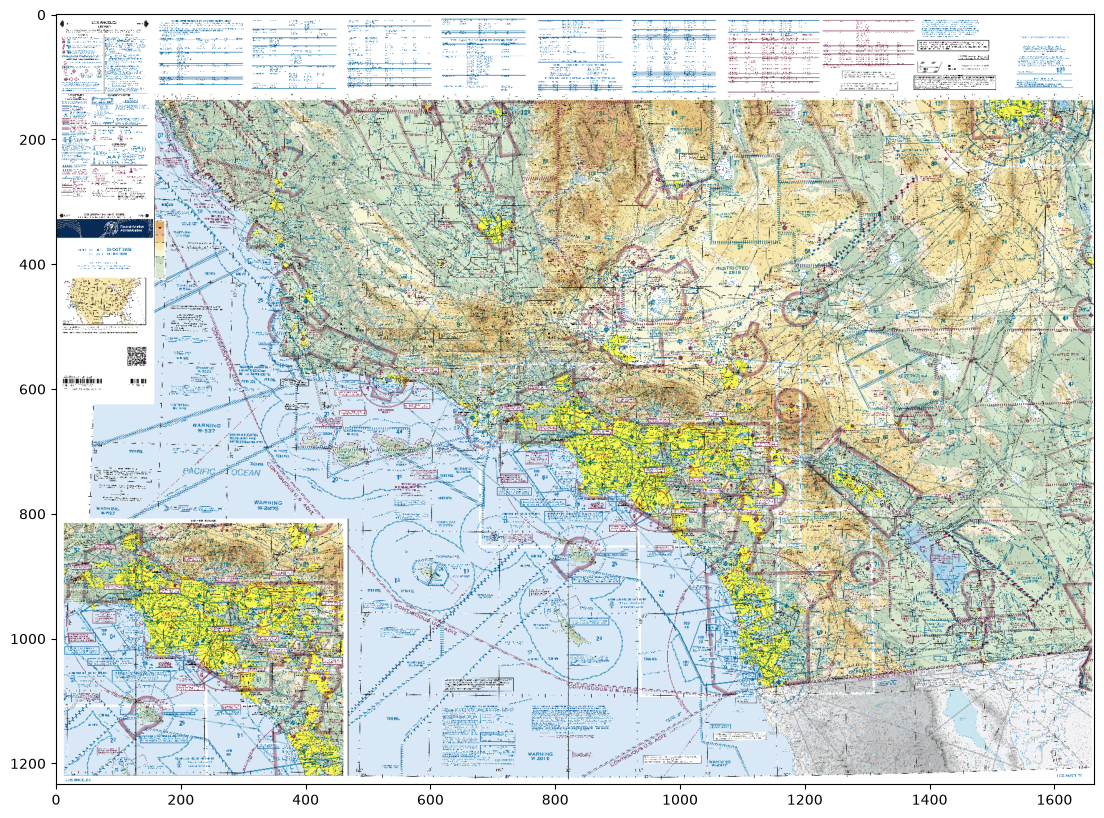

In [19]:
# Read the full chart at 1/10 size. This is fast and uses little memory.
small = src.read(1, out_shape=(src.height // 10, src.width // 10))

plt.figure(figsize=(16, 10))
plt.imshow(lut[small])
plt.show()

## Cell 4: Write the map area

In [20]:
MAP_ROW_MIN, MAP_ROW_MAX = 1500, 10500
MAP_COL_MIN, MAP_COL_MAX = 4700, 16500

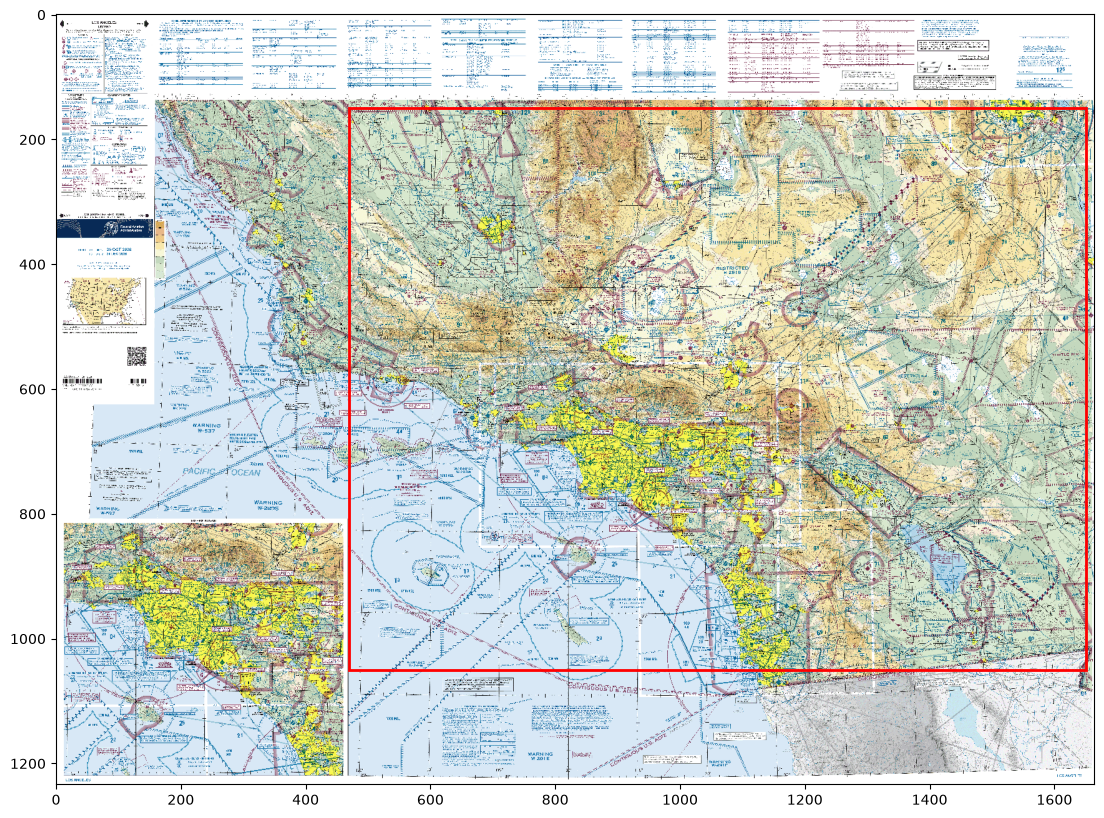

In [21]:
# Draw the map area rectangle on the 1/10 size image.
plt.figure(figsize=(16, 10))
plt.imshow(lut[small])
plt.gca().add_patch(plt.Rectangle(
    (MAP_COL_MIN / 10, MAP_ROW_MIN / 10),
    (MAP_COL_MAX - MAP_COL_MIN) / 10,
    (MAP_ROW_MAX - MAP_ROW_MIN) / 10,
    fill=False, edgecolor="red", linewidth=2,
))
plt.show()

### Note

The red area is used for making the training plots, not the area around.

## Cell 5: Load the NASR tables

In [22]:
# low_memory=False makes pandas find one data type for each column.
apt = pd.read_csv("../data/raw/29_Oct_2026_APT_CSV/APT_BASE.csv", low_memory=False)
nav = pd.read_csv("../data/raw/29_Oct_2026_NAV_CSV/NAV_BASE.csv", low_memory=False)

# Keep only airports. Remove heliports, seaplane bases, and other types.
apt = apt[apt["SITE_TYPE_CODE"] == "A"]

## Cell 6: Convert latitude and longitude to pixels

In [23]:
def to_pixels(df):
    # Convert latitude and longitude (EPSG:4326) to the chart projection.
    xs, ys = transform("EPSG:4326", src.crs, df["LONG_DECIMAL"].tolist(), df["LAT_DECIMAL"].tolist())

    # Convert the projection coordinates to pixel row and column.
    rows, cols = rowcol(src.transform, xs, ys)

    df = df.copy()
    df["px_row"] = rows
    df["px_col"] = cols
    return df

apt_px = to_pixels(apt)
nav_px = to_pixels(nav)

## Cell 7: Put all objects in one table and keep only the map area

In [24]:
# One table with the same columns for airports and navaids.
airports = pd.DataFrame({"type": "airport", "id": apt_px["ARPT_ID"], "px_row": apt_px["px_row"], "px_col": apt_px["px_col"]})
navaids = pd.DataFrame({"type": "navaid", "id": nav_px["NAV_ID"], "px_row": nav_px["px_row"], "px_col": nav_px["px_col"]})
objs = pd.concat([airports, navaids], ignore_index=True)

# IDs of the points with no symbol on the chart. Add them here.
EXCLUDE_IDS = []
objs = objs[~objs["id"].isin(EXCLUDE_IDS)]

# Keep only the objects inside the map area. This removes points on the legend border.
objs = objs[objs["px_row"].between(MAP_ROW_MIN, MAP_ROW_MAX) & objs["px_col"].between(MAP_COL_MIN, MAP_COL_MAX)]

print(objs["type"].value_counts())

type
airport    163
navaid      55
Name: count, dtype: int64


## Cell 8: Settings for the tiles

In [25]:
TILE = 1024     # Tile size in pixels.
STRIDE = 896    # Distance between tile starts. 1024 - 896 = 128 pixels of overlap.

# Output folders. The data/ folder is in .gitignore, so Git does not upload these files.
OUT_DIR = "../data/processed/los_angeles"
TILE_DIR = OUT_DIR + "/tiles"
os.makedirs(TILE_DIR, exist_ok=True)

## Cell 9: Cut the tiles and make the labels

If you run this cell again, delete the old tiles in `data/processed/los_angeles/tiles` first.

In [26]:
# The question is the same for all tiles. The answer is different for each tile.
QUESTION = "List all airports and navaids in this image with their pixel positions."
records = []

# Move across the map area, row by row.
for r in range(MAP_ROW_MIN, MAP_ROW_MAX - TILE + 1, STRIDE):
    for c in range(MAP_COL_MIN, MAP_COL_MAX - TILE + 1, STRIDE):

        # Find the objects inside this tile.
        inside = objs[objs["px_row"].between(r, r + TILE - 1) & objs["px_col"].between(c, c + TILE - 1)]

        # Skip tiles with no objects.
        if len(inside) == 0:
            continue

        # Read the tile and convert the color indexes to RGB.
        band = src.read(1, window=Window(c, r, TILE, TILE))
        tile_img = lut[band]

        # Save the tile image. The name contains its position on the chart.
        file_name = f"la_r{r}_c{c}.png"
        Image.fromarray(tile_img).save(os.path.join(TILE_DIR, file_name))

        # Sort the objects from top to bottom, then left to right. A fixed order makes the answers consistent.
        inside = inside.sort_values(["px_row", "px_col"])

        # Change the positions so that they start from the top-left corner of the tile.
        answer = [
            {"type": t, "id": i, "x": int(pc - c), "y": int(pr - r)}
            for t, i, pr, pc in zip(inside["type"], inside["id"], inside["px_row"], inside["px_col"])
        ]

        records.append({
            "image": "tiles/" + file_name,
            "row": r,
            "col": c,
            "question": QUESTION,
            "answer": json.dumps(answer),
        })

print("Tiles saved:", len(records))

/var/folders/hv/ssw7w9251n33ldwz20jqx8qw0000gn/T/ipykernel_45279/2035701266.py:17: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  band = src.read(1, window=Window(c, r, TILE, TILE))


Tiles saved: 88


## Cell 10: Split by area and save the labels

In [27]:
# The right 20% of the map area is the test area. The left 80% is the training area.
split_col = MAP_COL_MIN + int((MAP_COL_MAX - MAP_COL_MIN) * 0.8)
train, test = [], []

for rec in records:
    if rec["col"] + TILE <= split_col:
        train.append(rec)    # Tile is fully in the training area.
    elif rec["col"] >= split_col:
        test.append(rec)     # Tile is fully in the test area.
    # Tiles that cross the split line are not used. This prevents the same area in both sets.

# JSONL: one JSON record on each line.
def write_jsonl(path, rows):
    with open(path, "w") as f:
        for row in rows:
            f.write(json.dumps(row) + "\n")

write_jsonl(OUT_DIR + "/train.jsonl", train)
write_jsonl(OUT_DIR + "/test.jsonl", test)

print("Train tiles:", len(train))
print("Test tiles:", len(test))

Train tiles: 70
Test tiles: 12


## Cell 11: Check a random sample

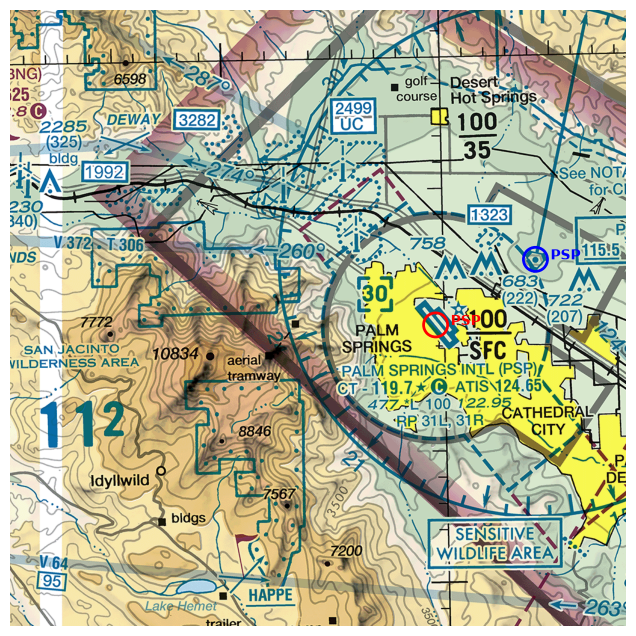

tiles/la_r6876_c11868.png
[{"type": "navaid", "id": "PSP", "x": 873, "y": 414}, {"type": "airport", "id": "PSP", "x": 707, "y": 523}]


In [29]:
# Each run shows a different random sample.
sample = random.choice(train)
img = Image.open(os.path.join(OUT_DIR, sample["image"]))
objects = json.loads(sample["answer"])

# Draw the label on the tile. Each mark must be on the correct symbol.
plt.figure(figsize=(8, 8))
plt.imshow(img)
for o in objects:
    color = "red" if o["type"] == "airport" else "blue"
    plt.scatter(o["x"], o["y"], s=300, facecolors="none", edgecolors=color, linewidths=2)
    plt.text(o["x"] + 25, o["y"], o["id"], color=color, fontsize=10, weight="bold")
plt.axis("off")
plt.show()

print(sample["image"])
print(sample["answer"])